# Earthquake Hazard Screening for Japan from USGS data from 2017 to 2024

**Question this mini-project is trying to answer:** Where is a damaging earthquake (M ≥ 6) most likely over the next decade in Japan and how much should we trust that answer?

**Condensed Approach**
1. **Clean** the USGS catalog and log every row removed, so the data prep is auditable.
2. Find the **magnitude of completeness (Mc)**: below it, small quakes are under-recorded and would bias any rate estimate.
3. Fit the **Gutenberg-Richter law** (a straight line on a log scale: each +1 magnitude unit means ~10× fewer events). Its slope, the *b-value*, lets us extrapolate from plentiful small quakes to rare large ones.
4. **Decluster** the catalog: aftershocks are not independent events, so they are removed before computing rates.
5. Turn rates into a **gridded probability map** (smoothed counts → annual rate → Poisson probability).
6. **Validate**: compare against plate boundaries and run an out-of-sample back-test.

Tools: pandas, NumPy, SciPy, GeoPandas, Matplotlib, Folium.

## Setup and parameters

In [1]:
#importing necessary libraries and setting up parameters for earthquake risk analysis
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from quake_risk import data, stats, hazard, tectonics, viz
from quake_risk.pipeline import DEFAULT_PLATES

viz.apply_style()

CSV_PATH      = "data/earthquakes.csv"   
YEAR_MIN, YEAR_MAX = None, None          
REGIONS       = ["Japan"]               
CELL_DEG      = 0.5                      
SIGMA_CELLS   = 2.0                                                            
TARGET_MAG    = 6.0                      
HORIZON_YEARS = 10                       
SEED          = 42                      

## 1. Load and clean the data



In [2]:
# filtering the catalog to japan and the years of interest(2017-2024)
display(data.load_catalog(CSV_PATH, YEAR_MIN, YEAR_MAX)[0]["Region"].value_counts().head(15).to_frame("events"))

df, report = data.load_catalog(CSV_PATH, YEAR_MIN, YEAR_MAX, regions=REGIONS)
display(report)
print(f"{len(df):,} events | {df.Time.min():%Y-%m-%d} to {df.Time.max():%Y-%m-%d} | "
      f"M {df.Magnitude.min():.1f}–{df.Magnitude.max():.1f} | depth {df.Depth_km.min():.0f}–{df.Depth_km.max():.0f} km")
df.head()

,events
Region,
Japan,10460
Russia,882
Taiwan,180
Kuril Islands,42
east of the Kuril Islands,41
China,23
South Korea,18
Sea of Japan,14
North Korea,11


,step,rows_remaining,rows_removed
0,Rows in raw file,11693,0
1,"Drop rows missing time, location, depth or mag...",11693,0
2,"Keep type == 'earthquake' (drop blasts, quarri...",11689,4
3,Remove duplicate event IDs,11689,0
4,Keep valid coordinates,11689,0
5,Keep only places labelled Japan,10460,1229


10,460 events | 2015-01-01 to 2024-12-31 | M 2.7–7.8 | depth 2–686 km


,Time,Latitude,Longitude,Depth_km,Magnitude,magType,id,Location,type,status,Year,Region
0,2015-01-01 05:01:10.640000+00:00,38.8957,142.0405,41.39,4.8,mb,usc000tb3v,"near the east coast of Honshu, Japan",earthquake,reviewed,2015,Japan
1,2015-01-01 06:56:58.510000+00:00,36.4411,139.7966,90.64,4.3,mb,usc000tb44,"2 km N of Mibu, Japan",earthquake,reviewed,2015,Japan
2,2015-01-01 13:57:14.670000+00:00,42.5720,141.8008,36.38,4.7,mb,usc000tb5l,"17 km ESE of Tomakomai, Japan",earthquake,reviewed,2015,Japan
3,2015-01-01 16:14:08.180000+00:00,32.0638,131.7949,38.61,4.2,mwr,usc000tb66,"28 km ESE of Takanabe, Japan",earthquake,reviewed,2015,Japan
4,2015-01-02 01:51:44.850000+00:00,35.7799,140.6482,16.75,4.2,mb,usc000tg40,"7 km N of Asahi, Japan",earthquake,reviewed,2015,Japan


## 2. Explore: where, how big, how deep

In [3]:
# regional summary of the catalog
display(hazard.regional_summary(df, df.Magnitude.min(), top=10))

,Region,events,max_mag,m5_plus,mean_depth_km,shallow_share
0,Japan,10460,7.8,973,68.48,0.79


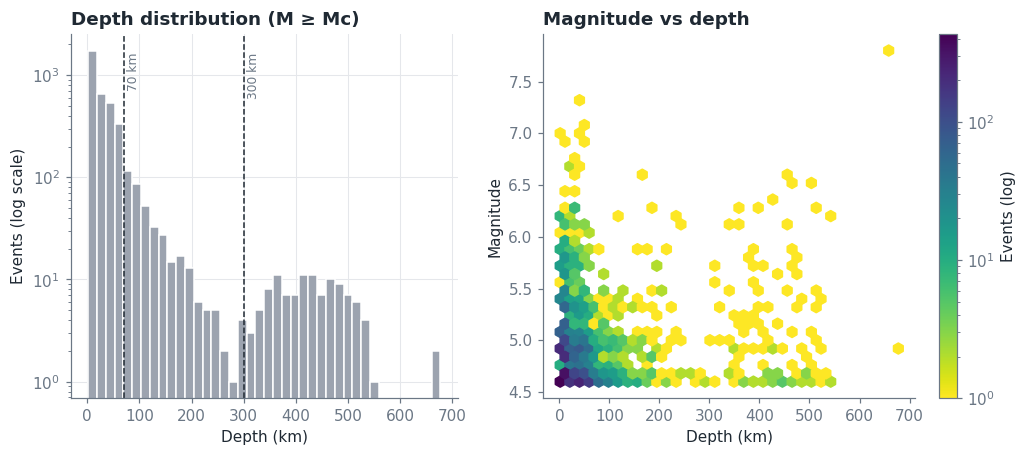

In [4]:
mc = stats.magnitude_of_completeness(df.Magnitude)
viz.fig_depth(df, mc); plt.show()

## 3. Completeness and the Gutenberg-Richter law

**Mc** is found with the maximum-curvature method (the most common magnitude bin, plus 0.2 as recommended by Woessner & Wiemer, 2005). Only events at or above Mc are used from here on. The **b-value** uses the Aki-Utsu maximum-likelihood estimator with a binning correction. The standard error is b/√N.

Mc = 4.6   b = 1.348 ± 0.022   (N = 3,753 events ≥ Mc)


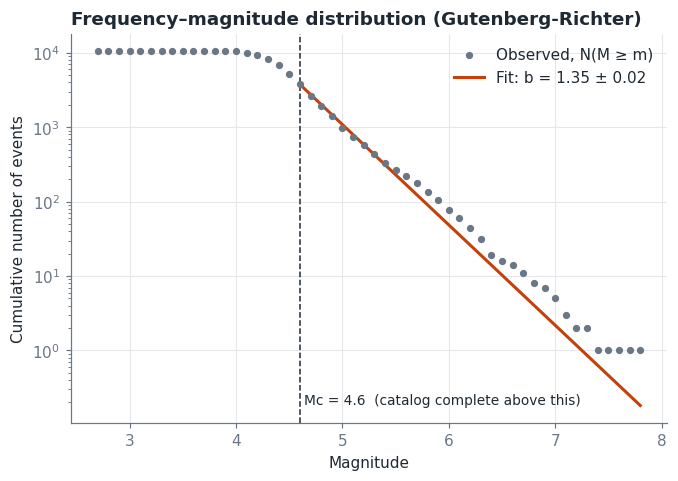

In [5]:
fit = stats.gutenberg_richter(df.Magnitude, mc)
print(f"Mc = {mc}   b = {fit['b']:.3f} ± {fit['b_se']:.3f}   (N = {fit['n']:,} events ≥ Mc)")
viz.fig_gutenberg_richter(df, fit); plt.show()

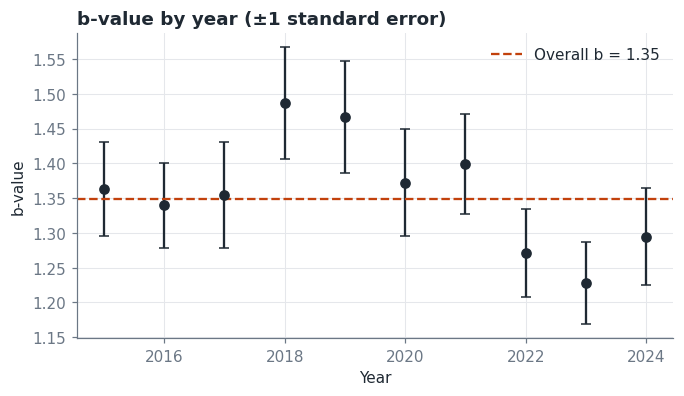

In [6]:
# Stability check: does b stay roughly constant year to year?
bty = stats.b_value_by_year(df, mc)
viz.fig_b_by_year(bty, fit["b"]); plt.show()

## 4. Decluster

Aftershock sequences make events *dependent*, but the probability model below assumes independence. The Gardner-Knopoff (1974) space-time windows flag smaller events near a larger one as aftershocks (or foreshocks). Only mainshocks feed the hazard rates.


Mainshocks: 1,300 of 3,753 events ≥ Mc (65% flagged as dependent)
b (all events) = 1.348   b (mainshocks) = 1.066 ± 0.030


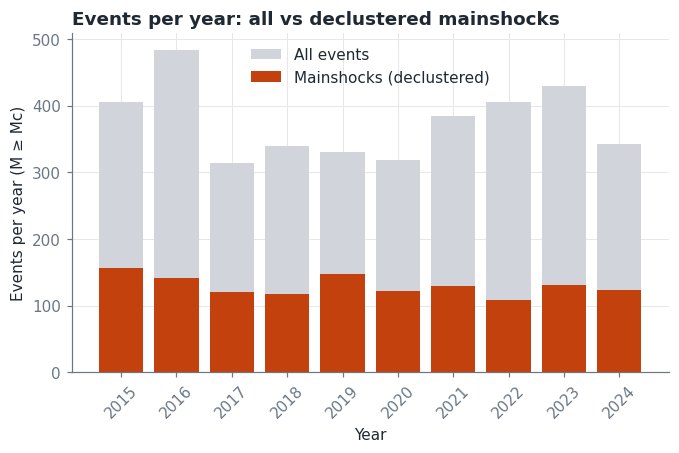

In [7]:
df["is_mainshock"] = stats.flag_mainshocks(df, mc)
above = df[df.Magnitude >= mc]
fit_main = stats.gutenberg_richter(above.loc[above.is_mainshock, "Magnitude"], mc)
print(f"Mainshocks: {above.is_mainshock.sum():,} of {len(above):,} events ≥ Mc "
      f"({100*(1-above.is_mainshock.mean()):.0f}% flagged as dependent)")
print(f"b (all events) = {fit['b']:.3f}   b (mainshocks) = {fit_main['b']:.3f} ± {fit_main['b_se']:.3f}")

annual = stats.annual_summary(df, mc)
viz.fig_annual(annual); plt.show()

## 5. Gridded hazard map

For each grid cell:
1. count mainshocks ≥ Mc and smooth with a Gaussian kernel (sparse cells borrow strength from neighbours);
2. divide by the catalog length to get an annual rate of M ≥ Mc;
3. scale to the target magnitude with Gutenberg-Richter: `rate(M≥Mt) = rate(M≥Mc) × 10^(−b(Mt−Mc))`;
4. convert to probability assuming a Poisson process: `P = 1 − exp(−rate × T)`.


In [8]:
grid, meta = hazard.hazard_grid(df, mc, fit_main["b"], CELL_DEG, SIGMA_CELLS, TARGET_MAG, HORIZON_YEARS)
print(f"Expected M≥{TARGET_MAG:g} mainshocks in catalog period: {meta['expected_events_target_in_catalog']:.1f}  |  "
      f"observed: {meta['observed_mainshocks_target_in_catalog']}")
display(grid.sort_values("p_target", ascending=False).head(10)
        [["lat_c", "lon_c", "p_target", "tier", "n_events", "max_mag", "mean_depth_km", "shallow_share"]].round(3))

Expected M≥6 mainshocks in catalog period: 41.8  |  observed: 56


,lat_c,lon_c,p_target,tier,n_events,max_mag,mean_depth_km,shallow_share
1256,35.75,140.75,0.103,Very high,36,6.1,40.090,1.000
1257,35.75,141.25,0.099,Very high,9,5.7,33.987,1.000
1203,35.25,140.75,0.099,Very high,15,5.9,36.459,1.000
1255,35.75,140.25,0.099,Very high,32,5.9,65.671,0.688
1309,36.25,140.75,0.099,Very high,20,5.3,51.117,0.900
1310,36.25,141.25,0.097,Very high,14,5.8,34.619,1.000
1202,35.25,140.25,0.096,Very high,15,5.2,46.180,0.867
1204,35.25,141.25,0.093,Very high,27,5.9,23.038,1.000
1308,36.25,140.25,0.093,Very high,15,5.2,70.982,0.400
833,31.75,141.25,0.092,Very high,0,NaN,NaN,NaN


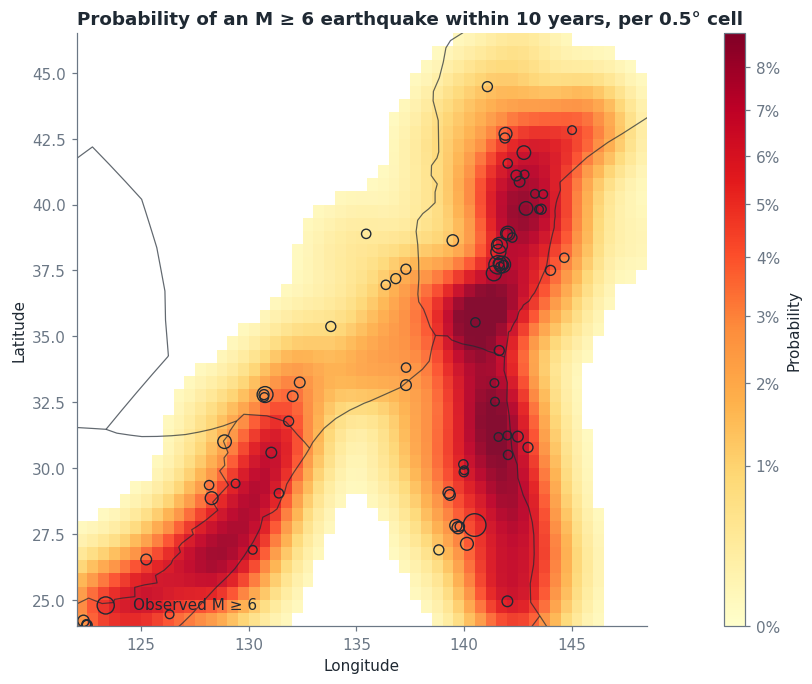

In [10]:
plates = tectonics.load_plates(DEFAULT_PLATES)
viz.fig_hazard_map(grid, meta, plates, df, big_mag=TARGET_MAG); plt.show()

## 6. Does the pattern make geological sense? Distance to plate boundaries

Most large earthquakes occur on or near plate boundaries. Distances are great-circle (geodesic) distances to the PB2002 plate-boundary model (Bird, 2003), not projected-map distances.

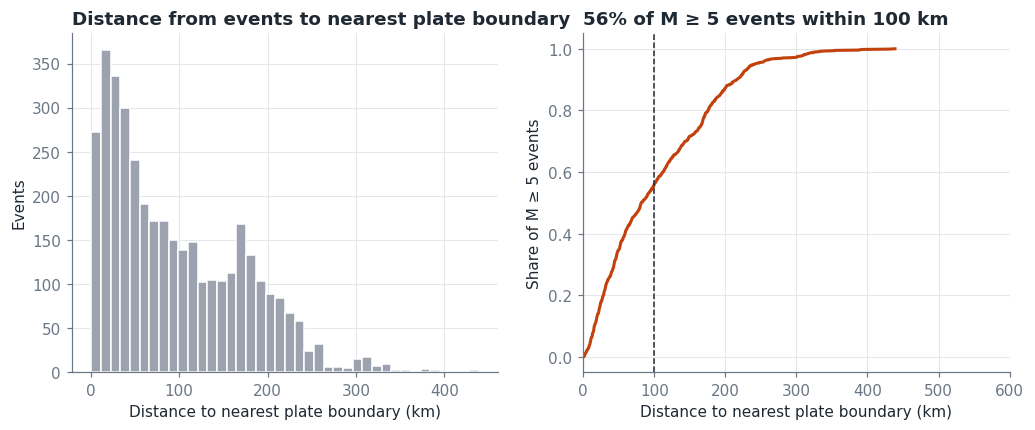

In [11]:
above = df[df.Magnitude >= mc].copy()
above["dist_km"] = tectonics.distance_to_boundary_km(above.Latitude, above.Longitude, plates)
viz.fig_plate_distance(above.dist_km.to_numpy(), above.Magnitude.to_numpy()); plt.show()

## 7. Out-of-sample back-test



Train ≤ 2020, test on 69 later M≥5.5 mainshocks: top 20% of area captured 75% of them (3.8× random)


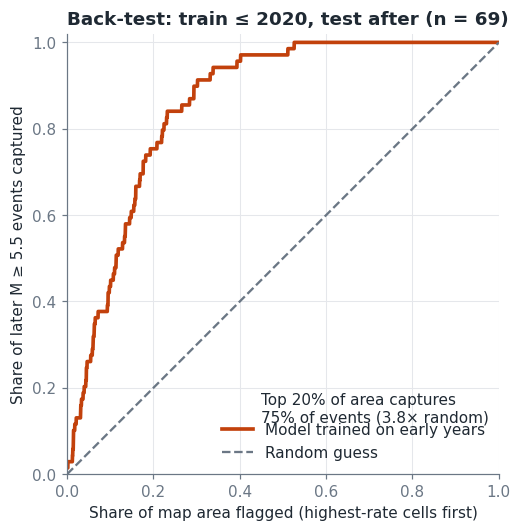

In [12]:
split_year = int(df.Year.min() + (df.Year.max() - df.Year.min()) * 0.6)
bt = hazard.backtest(df, mc, split_year, CELL_DEG, SIGMA_CELLS, test_mag=5.5)
print(f"Train ≤ {bt['split_year']}, test on {bt['n_test']} later M≥{bt['test_mag']:g} mainshocks: "
      f"top 20% of area captured {bt['hit_at_20pct_area']:.0%} of them ({bt['gain_at_20pct_area']:.1f}× random)")
viz.fig_backtest(bt); plt.show()

## 8. Interactive map for earthquakes
 The hazard grid, plate boundaries, a density heatmap, only the larger events as depth-coloured markers, and a time slider limited to M ≥ 5-ish events.

In [ ]:
from pathlib import Path
Path("outputs").mkdir(exist_ok=True)
m, info = viz.build_map(df, grid, meta, DEFAULT_PLATES, mc)
m.save("outputs/earthquake_risk_map.html")
print(info)
print("Saved outputs/earthquake_risk_map.html - open it in your browser.")

{'marker_min_mag': 5.5, 'n_markers': 268, 'slider_min_mag': 5.0, 'n_slider': 973}
Saved outputs/earthquake_risk_map.html - open it in your browser (it is too heavy to embed in the notebook).


## 9. What could the next decade look like? A simulation, not a prediction

Earthquakes cannot be predicted in time or place. What the fitted model *can* do is generate a random but statistically consistent future. For each map cell it draws a Poisson number of events from the cell's rate, magnitudes from the Gutenberg-Richter law (capped at M 9.0), uniform random times over the forecast window, positions inside the cell, and depths copied from nearby observed mainshocks.

Each seed gives a different, equally plausible decade. Read the result as *"this is the kind of activity the model implies"*, not as a list of events to expect. Aftershocks are not simulated.

The second chart is the more useful summary: how often an event of each size is expected somewhere in the study area, with the observed record alongside it as a reality check.

In [14]:
sim = hazard.simulate_catalog(grid, df, mc, fit_main["b"], HORIZON_YEARS, seed=SEED)
print(f"Simulated {len(sim):,} mainshocks >= M{mc} over {HORIZON_YEARS} years "
      f"({(sim.Magnitude >= 6).sum()} of M>=6, {(sim.Magnitude >= 7).sum()} of M>=7)")

sm, sim_info = viz.build_map(df, grid, meta, DEFAULT_PLATES, mc, sim=sim)
sm.save("outputs/earthquake_scenario_map.html")
print("Saved outputs/earthquake_scenario_map.html - open it in your browser and use the time slider.")

Simulated 1,280 mainshocks >= M4.6 over 10 years (41 of M>=6, 2 of M>=7)
Saved outputs/earthquake_scenario_map.html - open it in your browser and use the time slider.


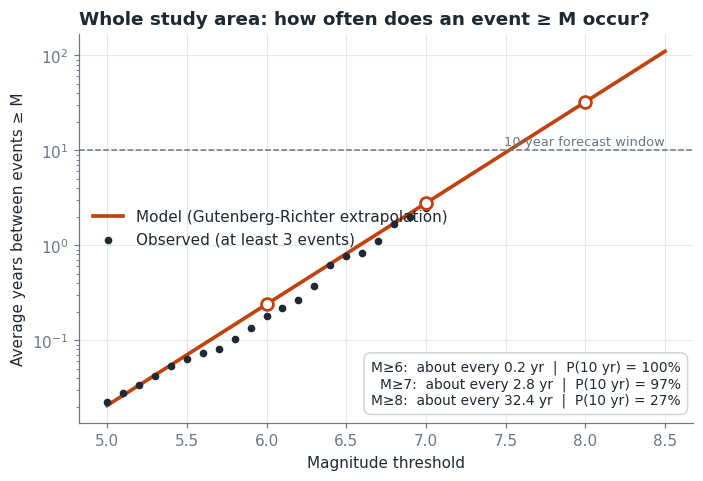

,magnitude,n_observed,return_period_model_yr,return_period_observed_yr,p_model,p_observed_rate
10,6.0,56,0.239,0.179,1.000,1.000
15,6.5,13,0.816,0.769,1.000,1.000
20,7.0,4,2.783,2.500,0.972,0.982
25,7.5,1,9.498,10.000,0.651,0.632
30,8.0,0,32.407,NaN,0.266,0.000


In [15]:
ex = hazard.areawide_exceedance(df, mc, fit_main["b"], HORIZON_YEARS)
viz.fig_exceedance(ex, meta, mc); plt.show()
ex[ex.magnitude.isin([6.0, 6.5, 7.0, 7.5, 8.0])].round(3)